# 06 · Decoding: MNE → MOABB → pyRiemann → Braindecode

## Goal
Compare transparent baselines, spatial filtering, covariance geometry, and a compact neural network using identical held-out runs.

**Scope:** a reproducible teaching analysis of public recordings, not clinical validation. Downloaded data are cached locally; no synthetic fallback is used. Each notebook runs independently.

## Setup
Use the environment in `README.md`. The default sample is deliberately small; results are descriptive unless explicitly stated otherwise.

In [2]:
from pathlib import Path
import sys
course_dir = Path.cwd() if (Path.cwd() / 'course_utils.py').exists() else Path.cwd() / 'EEG_from_ground_up'
assert (course_dir / 'course_utils.py').exists(), 'Open this notebook from the course folder or project root.'
sys.path.insert(0, str(course_dir.resolve()))
from course_utils import ROOT, DATA, OUTPUT, SEED, load_run, versions, style, save_table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from IPython.display import display
%matplotlib inline
style()
rng = np.random.default_rng(SEED)
display(versions().to_frame())

,version
numpy,2.5.4
scipy,1.18.1
pandas,3.0.6
matplotlib,3.11.2
mne,1.13.2
moabb,1.7.2
pyriemann,0.12
braindecode,1.8.1
torch,2.14.1
scikit-learn,1.9.1


## Steps

### 1. MOABB: consistent dataset access and task definition
MOABB standardizes dataset loading, task selection, and evaluation. We use its PhysionetMI loader and LeftRightImagery paradigm, then implement a transparent **held-out-run** evaluation using its metadata. We intentionally do not call ordinary trial-shuffled cross-validation a cross-run test.

Participants 1–3; eight prespecified motor-region channels; fixed 8–30 Hz filtering; task window +0.5 to +3.5 s. This is an offline, two-class, cue-driven problem. It does not test a no-command state or asynchronous control. The anatomical channel subset is fixed before seeing labels or scores.

In [4]:
from moabb.datasets import PhysionetMI
from moabb.paradigms import LeftRightImagery
from sklearn.preprocessing import LabelEncoder
SUBJECTS=[1,2,3]
CHANNELS=['C3','C4','Cz','FC3','FC4','FCz','CP3','CP4']
# Cache source EDFs through MNE before MOABB reads them.
for subject in SUBJECTS:
    for run in [4,8,12]:
        load_run(subject,run)
dataset=PhysionetMI()
dataset.feet_runs=[]  # Exclude unused hands/feet tasks; retain the three left/right runs.
paradigm=LeftRightImagery(fmin=8,fmax=30,tmin=.5,tmax=3.5,channels=CHANNELS)
moabb_epochs,labels,metadata=paradigm.get_data(dataset=dataset,subjects=SUBJECTS,return_epochs=True)
X=moabb_epochs.get_data()*1e6  # Explicit volts -> µV for all models.
encoder=LabelEncoder(); y=encoder.fit_transform(labels)
metadata=metadata.reset_index(drop=True)
metadata['trial_row']=np.arange(len(y))
# MOABB labels these source runs 0/1/2; retain the original EDF run identity too.
run_mapping={str(i):run for i,run in enumerate(dataset.hand_runs)}
metadata['edf_run']=metadata['run'].astype(str).map(run_mapping)
assert metadata['edf_run'].notna().all(), 'Inspect changed MOABB run identifiers before proceeding.'
metadata['label']=labels
metadata['group']=metadata[['subject','session','run']].astype(str).agg('/'.join,axis=1)
display(metadata.groupby(['subject','session','run','label']).size().unstack(fill_value=0))
print('Classes:',encoder.classes_,'; X [trials, channels, samples]:',X.shape)
save_table(metadata,'06_trial_metadata.csv')

/Users/trush/Documents/Research/Synaptrix/synaptrixmotorimagerydata/EEG_from_ground_up/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


label                left_hand  right_hand
subject session run                       
1       0       0            8           7
                1            8           7
                2            7           8
2       0       0            7           8
                1            8           7
                2            8           7
3       0       0            8           7
                1            7           8
                2            8           7

Classes: ['left_hand' 'right_hand'] ; X [trials, channels, samples]: (135, 8, 481)


,subject,session,run,trial_row,edf_run,label,group
0,1,0,0,0,4,right_hand,1/0/0
1,1,0,0,1,4,left_hand,1/0/0
2,1,0,0,2,4,left_hand,1/0/0
3,1,0,0,3,4,right_hand,1/0/0
4,1,0,0,4,4,right_hand,1/0/0
...,...,...,...,...,...,...,...
130,3,0,2,130,12,left_hand,3/0/2
131,3,0,2,131,12,right_hand,3/0/2
132,3,0,2,132,12,left_hand,3/0/2
133,3,0,2,133,12,right_hand,3/0/2


### 2. Freeze a split before fitting
Within each participant, reserve the last run (ordered by MOABB run ID) for testing and use earlier runs for training. This tests transfer to another run within the recorded session, not to a new participant or day. No hyperparameters are chosen using test scores; deep learning uses a fixed 20-epoch budget. For tuning, add an inner run-grouped validation loop.

All methods see the same arrays and split. Fixed filters act within individual source runs; learned CSP, scaling, and tangent-space references are fitted only on training trials. No overlapping trial crops are created.

In [5]:
splits=[]; split_rows=[]
for subject in SUBJECTS:
    idx=np.flatnonzero(metadata.subject.to_numpy()==subject)
    groups=sorted(metadata.loc[idx,'group'].unique())
    assert len(groups)>=3, 'Need at least three runs for this demonstration.'
    test=idx[metadata.loc[idx,'group'].to_numpy()==groups[-1]]
    train=np.setdiff1d(idx,test)
    assert set(metadata.loc[train,'group']).isdisjoint(metadata.loc[test,'group'])
    assert set(y[train])==set(y[test])=={0,1}
    splits.append((subject,train,test))
    split_rows.extend({'trial_row':int(i),'subject':subject,'split':role} for role,ids in [('train',train),('test',test)] for i in ids)
save_table(pd.DataFrame(split_rows),'06_frozen_split.csv')
display(pd.DataFrame([{'subject':s,'train_trials':len(tr),'test_trials':len(te)} for s,tr,te in splits]))

,subject,train_trials,test_trials
0,1,30,15
1,2,30,15
2,3,30,15


### 3. MNE and pyRiemann baselines
Compare a dummy classifier, log-variance + shrinkage LDA, CSP + shrinkage LDA, covariance minimum-distance-to-mean (MDM), and covariance tangent-space + logistic regression.

CSP learns spatial projections that contrast class variances. A covariance matrix summarizes channel variances and cross-channel co-fluctuation; it discards much temporal ordering. OAS shrinkage helps keep covariance estimates positive definite. Tangent-space features depend on a reference covariance fitted on the training set. Neither covariance classification nor good accuracy establishes connectivity or causality.
For a centered trial matrix $X\in\mathbb{R}^{C\times T}$, the sample covariance is $\hat\Sigma=XX^\top/(T-1)$. Shrinkage combines it with a scaled identity: $\Sigma_\lambda=(1-\lambda)\hat\Sigma+\lambda\,\mathrm{tr}(\hat\Sigma)I/C$; the estimator determines $\lambda$ from data.

CSP solves a class-variance problem such as $\Sigma_1w=\lambda(\Sigma_1+\Sigma_2)w$. The learned filters must be fitted inside the training split. Spatial filters are not automatically source-localization maps.

For symmetric positive-definite covariance matrices $A,B$, the affine-invariant distance is $d(A,B)=\|\log(A^{-1/2}BA^{-1/2})\|_F$. MDM assigns the nearest class mean under this geometry. Tangent-space classification maps covariances around a training-derived reference and applies an ordinary classifier. Scaling and regularization still matter.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from mne.decoding import CSP
from pyriemann.estimation import Covariances
from pyriemann.classification import MDM
from pyriemann.tangentspace import TangentSpace

def log_variance(data):
    return np.log(np.maximum(data.var(axis=-1),1e-12))

models={
    'Dummy':make_pipeline(FunctionTransformer(log_variance),DummyClassifier(strategy='prior')),
    'Log variance + LDA':make_pipeline(FunctionTransformer(log_variance),StandardScaler(),LinearDiscriminantAnalysis(solver='lsqr',shrinkage='auto')),
    'CSP + LDA':make_pipeline(CSP(n_components=4,reg='oas',log=True,norm_trace=False),LinearDiscriminantAnalysis(solver='lsqr',shrinkage='auto')),
    'Riemann MDM':make_pipeline(Covariances(estimator='oas'),MDM(metric='riemann')),
    'Tangent + logistic':make_pipeline(Covariances(estimator='oas'),TangentSpace(metric='riemann'),StandardScaler(),LogisticRegression(C=1,max_iter=1000,random_state=SEED)),
}
results=[]; predictions=[]
def record(name,subject,test,pred,prob):
    results.append({'model':name,'subject':subject,'test_trials':len(test),
        'balanced_accuracy':balanced_accuracy_score(y[test],pred),'ROC_AUC':roc_auc_score(y[test],prob)})
    predictions.extend({'model':name,'subject':subject,'trial_row':int(i),'true':int(a),'predicted':int(b),'p_class_1':float(p)} for i,a,b,p in zip(test,y[test],pred,prob))

for subject,train,test in splits:
    for name,pipeline in models.items():
        fitted=clone(pipeline).fit(X[train],y[train])
        record(name,subject,test,fitted.predict(X[test]),fitted.predict_proba(X[test])[:,1])
display(pd.DataFrame(results))

,model,subject,test_trials,balanced_accuracy,ROC_AUC
0,Dummy,1,15,0.500000,0.500000
1,Log variance + LDA,1,15,0.544643,0.660714
2,CSP + LDA,1,15,0.812500,0.910714
3,Riemann MDM,1,15,0.750000,0.928571
4,Tangent + logistic,1,15,0.625000,0.857143
5,Dummy,2,15,0.500000,0.500000
6,Log variance + LDA,2,15,0.526786,0.607143
7,CSP + LDA,2,15,0.785714,0.910714
8,Riemann MDM,2,15,0.857143,0.910714
9,Tangent + logistic,2,15,0.857143,0.946429


### 4. Braindecode EEGNet on exactly the same split
EEGNet learns temporal and spatial convolutional features. This is a small fixed-budget comparison, not a tuned deep-learning benchmark. Twenty epochs and one seed do not establish a neural network’s potential or superiority.

Scale each channel using training-only mean and standard deviation. Use CPU execution and a fixed seed for a reproducible tutorial. Keep the test set out of normalization, training, early stopping, and architecture selection. We use Braindecode’s model with an explicit PyTorch training loop so every update is visible.

Trainable parameters in final EEGNet: 794


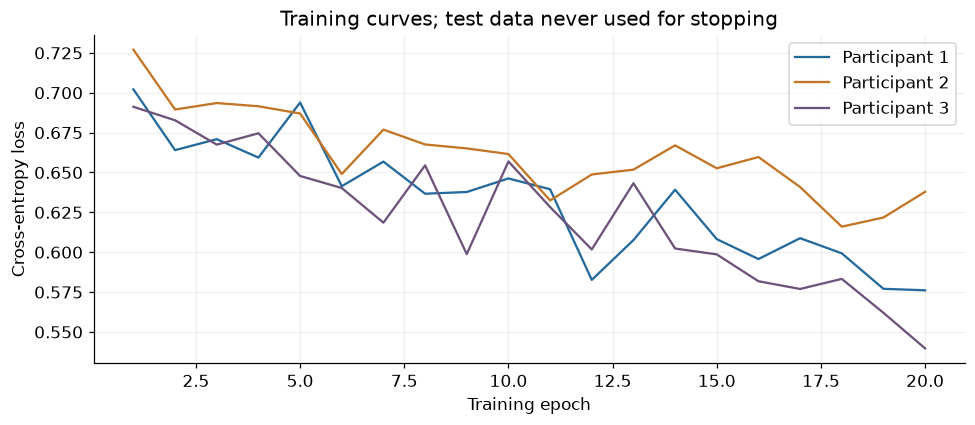

,subject,epoch,training_loss
0,1,1,0.702089
1,1,2,0.663972
2,1,3,0.670851
3,1,4,0.659304
4,1,5,0.693831
5,1,6,0.641363
6,1,7,0.656766
7,1,8,0.636650
8,1,9,0.637726
9,1,10,0.646224


In [10]:
import torch
from torch.utils.data import TensorDataset,DataLoader
from braindecode.models import EEGNet
import random
TRAIN_EPOCHS=20
BATCH_SIZE=16
history=[]
torch.set_num_threads(2)
for subject,train,test in splits:
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    mu=X[train].mean(axis=(0,2),keepdims=True)
    sigma=np.maximum(X[train].std(axis=(0,2),keepdims=True),1e-6)
    xtrain=((X[train]-mu)/sigma).astype('float32')
    xtest=((X[test]-mu)/sigma).astype('float32')
    net=EEGNet(n_chans=X.shape[1],n_outputs=2,n_times=X.shape[2],
        sfreq=moabb_epochs.info['sfreq'],F1=4,D=2,F2=8,drop_prob=.25)
    optimizer=torch.optim.Adam(net.parameters(),lr=1e-3)
    loss_fn=torch.nn.CrossEntropyLoss()
    generator=torch.Generator().manual_seed(SEED)
    loader=DataLoader(TensorDataset(torch.from_numpy(xtrain),torch.tensor(y[train],dtype=torch.long)),
        batch_size=BATCH_SIZE,shuffle=True,generator=generator)
    for epoch in range(TRAIN_EPOCHS):
        net.train(); total_loss=0
        for xb,yb in loader:
            optimizer.zero_grad(); logits=net(xb); loss=loss_fn(logits,yb)
            loss.backward(); optimizer.step(); total_loss+=loss.item()*len(yb)
        history.append({'subject':subject,'epoch':epoch+1,'training_loss':total_loss/len(train)})
    net.eval()
    with torch.no_grad(): probs=net(torch.from_numpy(xtest)).softmax(dim=1).numpy()
    record('EEGNet (20 epochs)',subject,test,probs.argmax(axis=1),probs[:,1])
print('Trainable parameters in final EEGNet:',sum(p.numel() for p in net.parameters() if p.requires_grad))
history=pd.DataFrame(history)
fig,ax=plt.subplots()
for s,g in history.groupby('subject'): ax.plot(g.epoch,g.training_loss,label=f'Participant {s}')
ax.set(xlabel='Training epoch',ylabel='Cross-entropy loss',title='Training curves; test data never used for stopping')
ax.legend(); plt.tight_layout(); plt.show()
save_table(history,'06_EEGNet_training_history.csv')

### 5. Compare results without overclaiming
Balanced accuracy is the mean class recall; its binary chance reference is 0.5. AUC measures ranking, not probability calibration. Show every participant rather than only a grand mean. Test sets are small; no population superiority claim is justified.

The confusion matrix pools held-out predictions for description. Participant-level mean performance gives each participant equal weight. These quantities need not agree when trial counts differ.

subject,1,2,3
model,,,
CSP + LDA,0.812,0.786,0.545
Dummy,0.500,0.500,0.500
EEGNet (20 epochs),0.500,0.491,0.500
Log variance + LDA,0.545,0.527,0.420
Riemann MDM,0.750,0.857,0.473
Tangent + logistic,0.625,0.857,0.545


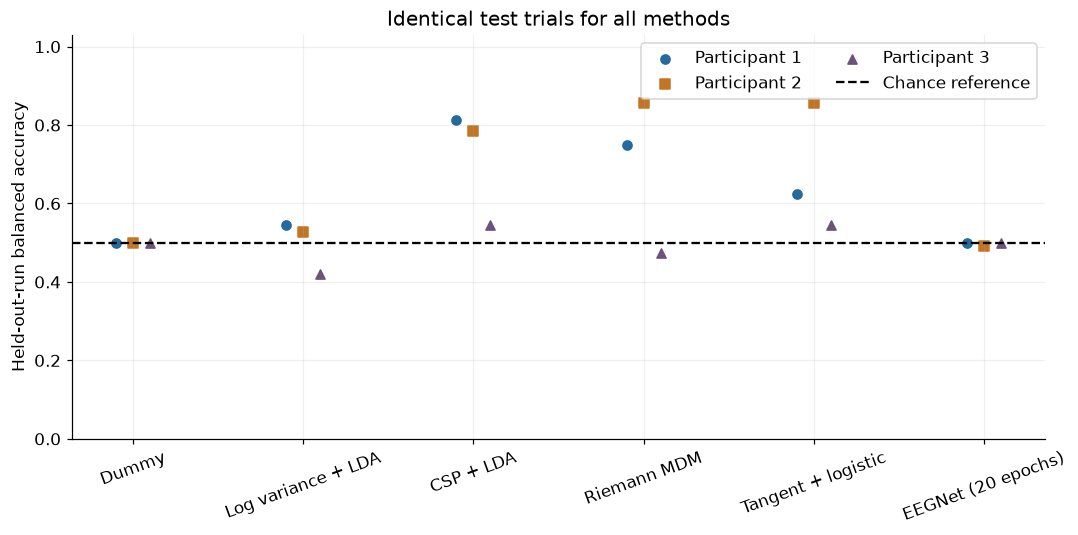

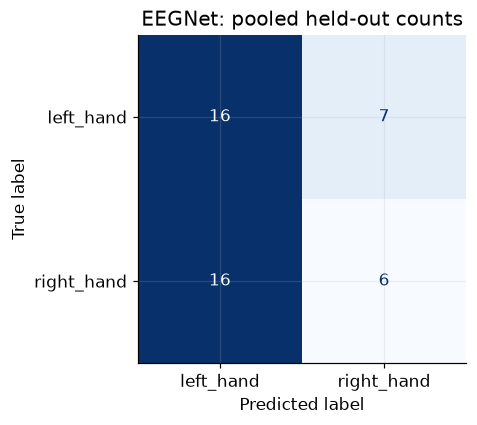

In [12]:
results=pd.DataFrame(results); predictions=pd.DataFrame(predictions)
save_table(results,'06_model_results.csv'); save_table(predictions,'06_predictions.csv')
display(results.pivot(index='model',columns='subject',values='balanced_accuracy').round(3))
fig,ax=plt.subplots(figsize=(10,5))
order=list(models)+['EEGNet (20 epochs)']
for k,s in enumerate(SUBJECTS):
    vals=results[results.subject==s].set_index('model').loc[order,'balanced_accuracy']
    ax.scatter(np.arange(len(order))+(k-1)*.1,vals,label=f'Participant {s}',marker=['o','s','^'][k])
ax.axhline(.5,color='black',ls='--',label='Chance reference')
ax.set(xticks=np.arange(len(order)),xticklabels=order,ylim=(0,1.03),ylabel='Held-out-run balanced accuracy',title='Identical test trials for all methods')
ax.tick_params(axis='x',labelrotation=20); ax.legend(ncol=2); plt.tight_layout(); plt.show()
p=predictions[predictions.model=='EEGNet (20 epochs)']
ConfusionMatrixDisplay(confusion_matrix(p.true,p.predicted,labels=[0,1]),display_labels=encoder.classes_).plot(cmap='Blues',colorbar=False)
plt.title('EEGNet: pooled held-out counts'); plt.tight_layout(); plt.show()

## Checks
Verify split separation, consistent test trial IDs across models, finite predictions, and complete scores. These checks establish implementation consistency, not scientific generalization.

In [14]:
assert np.isfinite(X).all()
assert len(results)==len(SUBJECTS)*(len(models)+1)
for subject,train,test in splits:
    for model in order:
        rows=predictions[(predictions.subject==subject)&(predictions.model==model)]
        assert set(rows.trial_row)==set(test)
assert predictions.p_class_1.between(0,1).all()
print('All models evaluated on identical held-out trials; results saved.')

All models evaluated on identical held-out trials; results saved.


## Next Steps
1. Add participants, then run a **cross-subject** evaluation with MOABB’s `CrossSubjectEvaluation` and prespecified models. Do not label this notebook’s within-person results cross-subject evidence.
2. For separate-day transfer, select a documented multi-session dataset, such as BNCI2014_001, and use `CrossSessionEvaluation`. Verify task labels, channel count, and protocol before comparing datasets.
3. Add nested run-grouped model selection, multiple random seeds, and paired participant-level uncertainty. Keep a final test set untouched.
4. Add wavelet-derived or dynamical-systems features only as additional pipelines under the same split. Include ablations and suitable surrogate/null controls.
5. For real-time work, replace offline zero-phase filtering with a validated causal pipeline; measure latency and false activations in a no-command state.

**Exercises:** implement leave-one-run-out evaluation; compare average performance across outer folds without tuning on them. Explain why a deep model can fit training data while failing on another run. Ask whether performance comes from neural activity, cue responses, or residual artifacts.

## Sources and further reading
Original teaching code; the resources below provide APIs, methodological guidance, and dataset provenance. No tutorial text or full external notebook is reproduced.

- [PhysioNet dataset and protocol](https://physionet.org/content/eegmmidb/1.0.0/)
- [MOABB getting started](https://moabb.neurotechx.com/docs/auto_examples/tutorials/tutorial_0_plot_getting_started.html)
- [MOABB PhysionetMI](https://moabb.neurotechx.com/docs/generated/moabb.datasets.PhysionetMI.html)
- [MNE CSP](https://mne.tools/stable/auto_examples/decoding/decoding_csp_eeg.html)
- [pyRiemann tangent space](https://pyriemann.readthedocs.io/en/latest/generated/pyriemann.tangentspace.TangentSpace.html)
- [Braindecode EEGNet](https://braindecode.org/stable/generated/braindecode.models.EEGNet.html)
- [BNCI datasets](https://bnci-horizon-2020.eu/database/data-sets)